# Customer Churn Prediction — Part 1: Exploratory Data Analysis (EDA)

**Goal of the project:** predict whether a bank customer will leave the bank (`Exited = 1`) so the bank can act before they go.


**In this notebook:** 
1. data overview
2. cleaning
3. univariate analysis
4. bivariate analysis (against churn)
5. correlations
6. outliers
7. key findings.

## 1. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the data

In [3]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Column description
1. RowNumber – Unique row number/record identifier. No predictive value.
2. CustomerId – Unique ID assigned to each customer. No predictive value.
3. Surname – Customer's surname/name. Generally not useful for prediction.
4. CreditScore – Customer's credit score; indicates creditworthiness.
5. Geography – Customer's country: France, Spain, or Germany.
6. Gender – Customer's gender: Male or Female.
7. Age – Customer's age in years.
8. Tenure – Number of years the customer has been with the bank.
9. Balance – Amount of money maintained in the customer's bank account.
10. NumOfProducts – Number of banking products/services used by the customer.
11. HasCrCard – Indicates whether the customer has a credit card:
    1 = Has credit card
    0 = Does not have credit card
12. IsActiveMember – Indicates whether the customer is an active bank member:
    1 = Active member
    0 = Inactive member
13. EstimatedSalary – Estimated annual salary of the customer.
14. Exited – Target variable indicating customer churn:
    1 = Customer left the bank
    0 = Customer stayed with the bank

## 3. Basic data inspection

In [4]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (10000, 14)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
print("Unique values per column:")
print(df.nunique())

Unique values per column:
RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64


**Observations**
- No missing values and no duplicate rows, so no imputation is needed.
- `RowNumber` and `CustomerId` are unique for every row and `Surname` has thousands of different values — none of them help predict churn, so we drop them.

## 4. Data cleaning

In [11]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

In [10]:
target = "Exited"
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography", "Gender", "HasCrCard", "IsActiveMember"]

In [11]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 5. Target variable — is the data balanced?

In [13]:
counts = pd.DataFramedf[target].value_counts()/100

Exited
0    79.63
1    20.37
Name: count, dtype: float64

NameError: name 'counts' is not defined

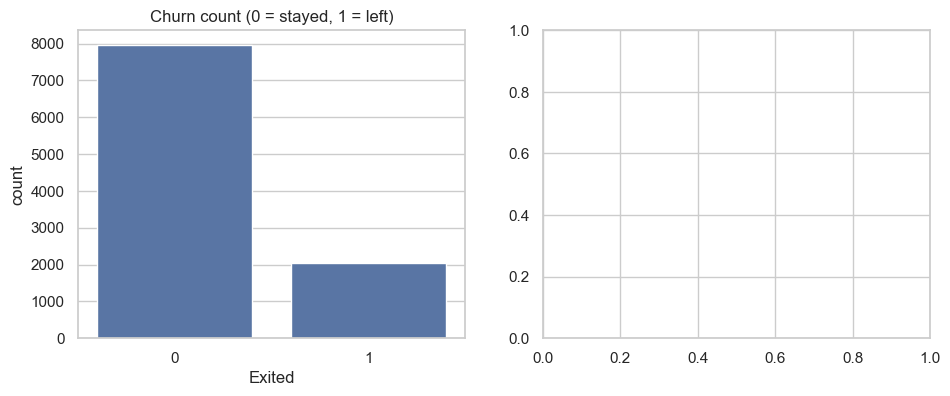

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x=target, ax=ax[0])
ax[0].set_title("Churn count (0 = stayed, 1 = left)")
ax[1].pie(counts, labels=["Stayed", "Left"], autopct="%1.1f%%", startangle=90,
          colors=["b", "r"])
ax[1].set_title("Churn share")
plt.tight_layout()
plt.show()

**Observation:** only about 1 in 5 customers churned, so the data is **imbalanced**. This matters later:
plain *accuracy* can look good (~80%) even for a model that predicts "stays" for everyone, so in the modelling notebook we will focus on **recall, F1 and ROC-AUC** as well, and try `class_weight='balanced'` while tuning.

## 6. Univariate analysis

### 6.1 Numerical features

In [1]:
# Plots all numerical columns
df[num_cols].hist(figsize=(16, 8), layout=(2, 3), color="#4c72b0")
plt.tight_layout()
plt.show()


NameError: name 'df' is not defined

In [28]:
print("Skewness of numerical columns:")
print(df[num_cols].skew().round(2))


Skewness of numerical columns:
CreditScore       -0.07
Age                1.01
Tenure             0.01
Balance           -0.14
NumOfProducts      0.75
EstimatedSalary    0.00
dtype: float64


In [29]:
print("Customers with zero balance: {:.1f}%".format((df["Balance"] == 0).mean() * 100))

Customers with zero balance: 36.2%


**Observations**
- `Age` is right-skewed: most customers are 30–45 years old.
- `CreditScore` is roughly bell-shaped with a small pile-up at the maximum (850).
- `Balance` has a huge spike at **0** (about a third of customers) and is roughly normal for the rest.
- `Tenure` and `EstimatedSalary` are almost uniformly distributed.

### 6.2 Categorical features

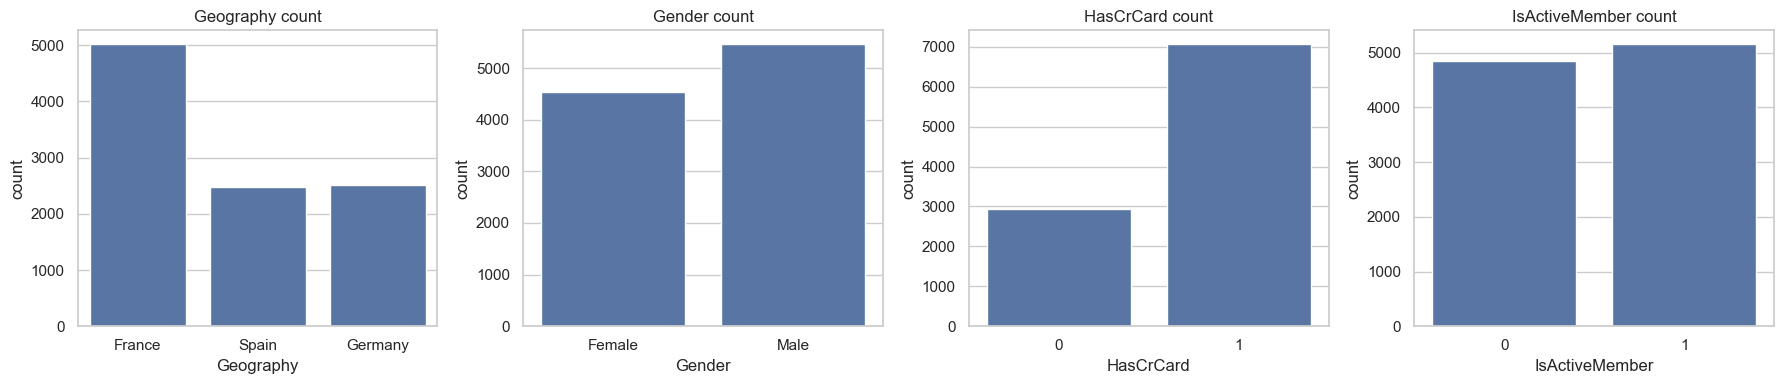

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, ax=ax, color="#4c72b0")
    ax.set_title(f"{col} count")
plt.tight_layout()
plt.show()

**Observations:** about half of the customers are from France, with Germany and Spain sharing the rest; the gender split is fairly even; most customers have a credit card; and active/inactive members are close to 50/50.

## 7. Bivariate analysis — what is related to churn?

### 7.1 Churn rate for each category

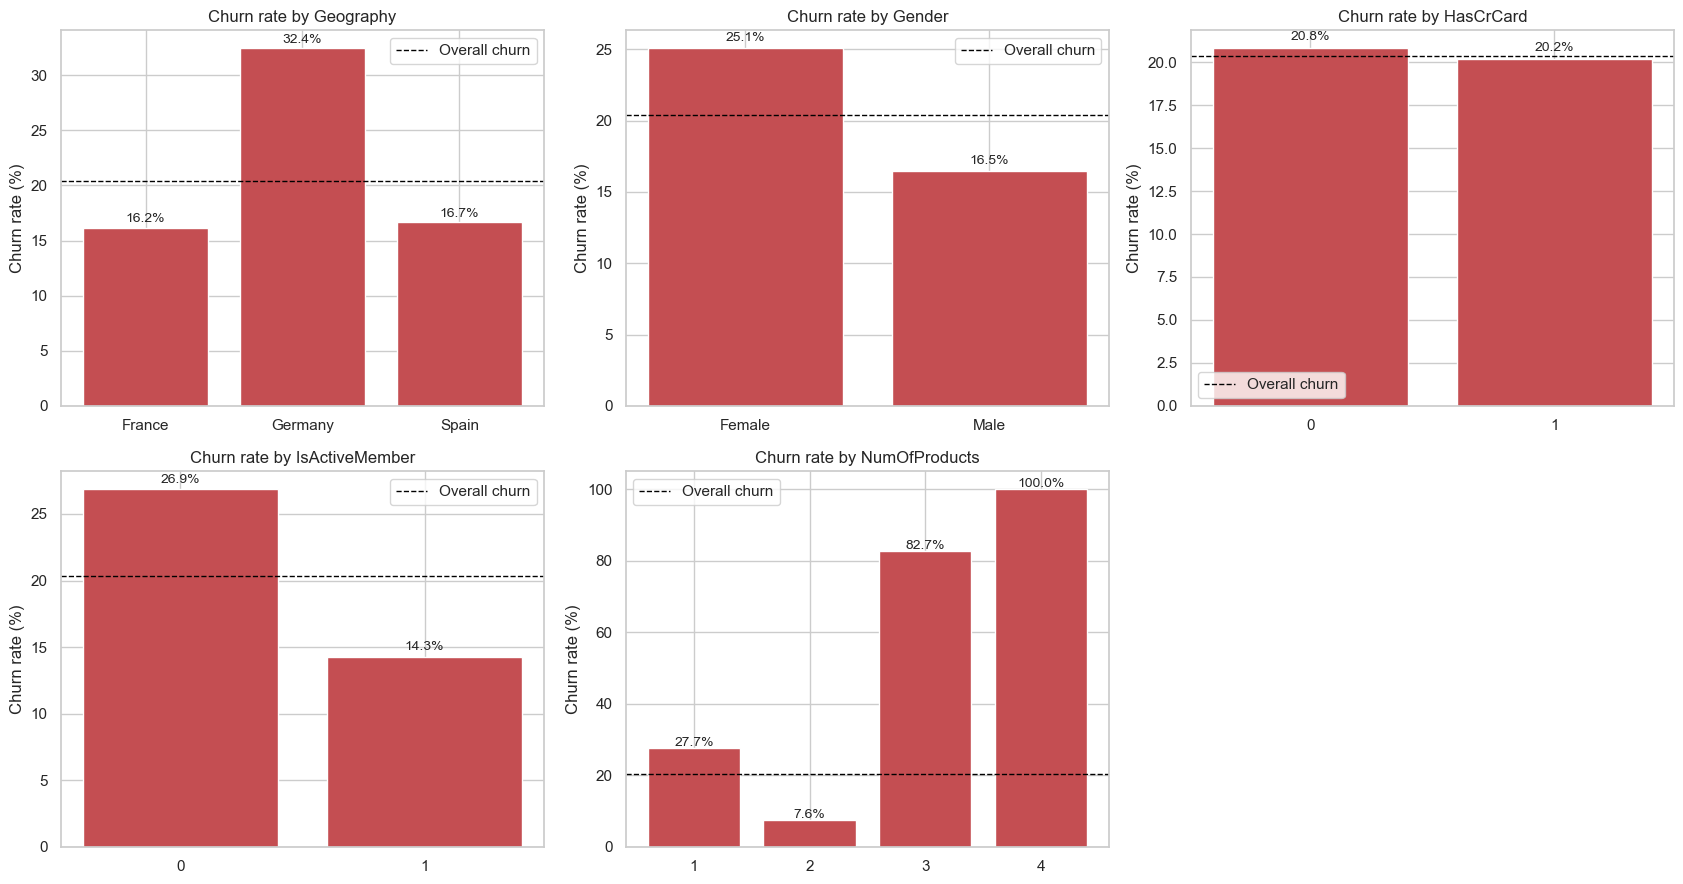

In [43]:
def churn_rate_plot(col, ax):
    rate = df.groupby(col)[target].mean() * 100
    bars = ax.bar(rate.index.astype(str), rate.values, color="#c44e52")
    ax.axhline(df[target].mean() * 100, color="black", linestyle="--", linewidth=1,
               label="Overall churn")
    for bar, value in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f"{value:.1f}%",
                ha="center", fontsize=10)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.legend()

cols_to_plot = ["Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), cols_to_plot):
    churn_rate_plot(col, ax)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [44]:
print(df.groupby("NumOfProducts")[target].agg(["count", "mean"]).rename(columns={"mean": "churn_rate"}).round(3))

               count  churn_rate
NumOfProducts                   
1               5084       0.277
2               4590       0.076
3                266       0.827
4                 60       1.000


**Observations**
- **Geography:** customers in **Germany** churn at roughly *double* the rate of France and Spain.
- **Gender:** female customers churn more than male customers.
- **IsActiveMember:** inactive members churn far more than active members.
- **HasCrCard:** having a credit card makes almost no difference.
- **NumOfProducts:** customers with **1 product** churn a lot, **2 products** is the safest group, and customers with **3–4 products** churn at extremely high rates (though there are only a few of them).

### 7.2 Numerical features vs churn

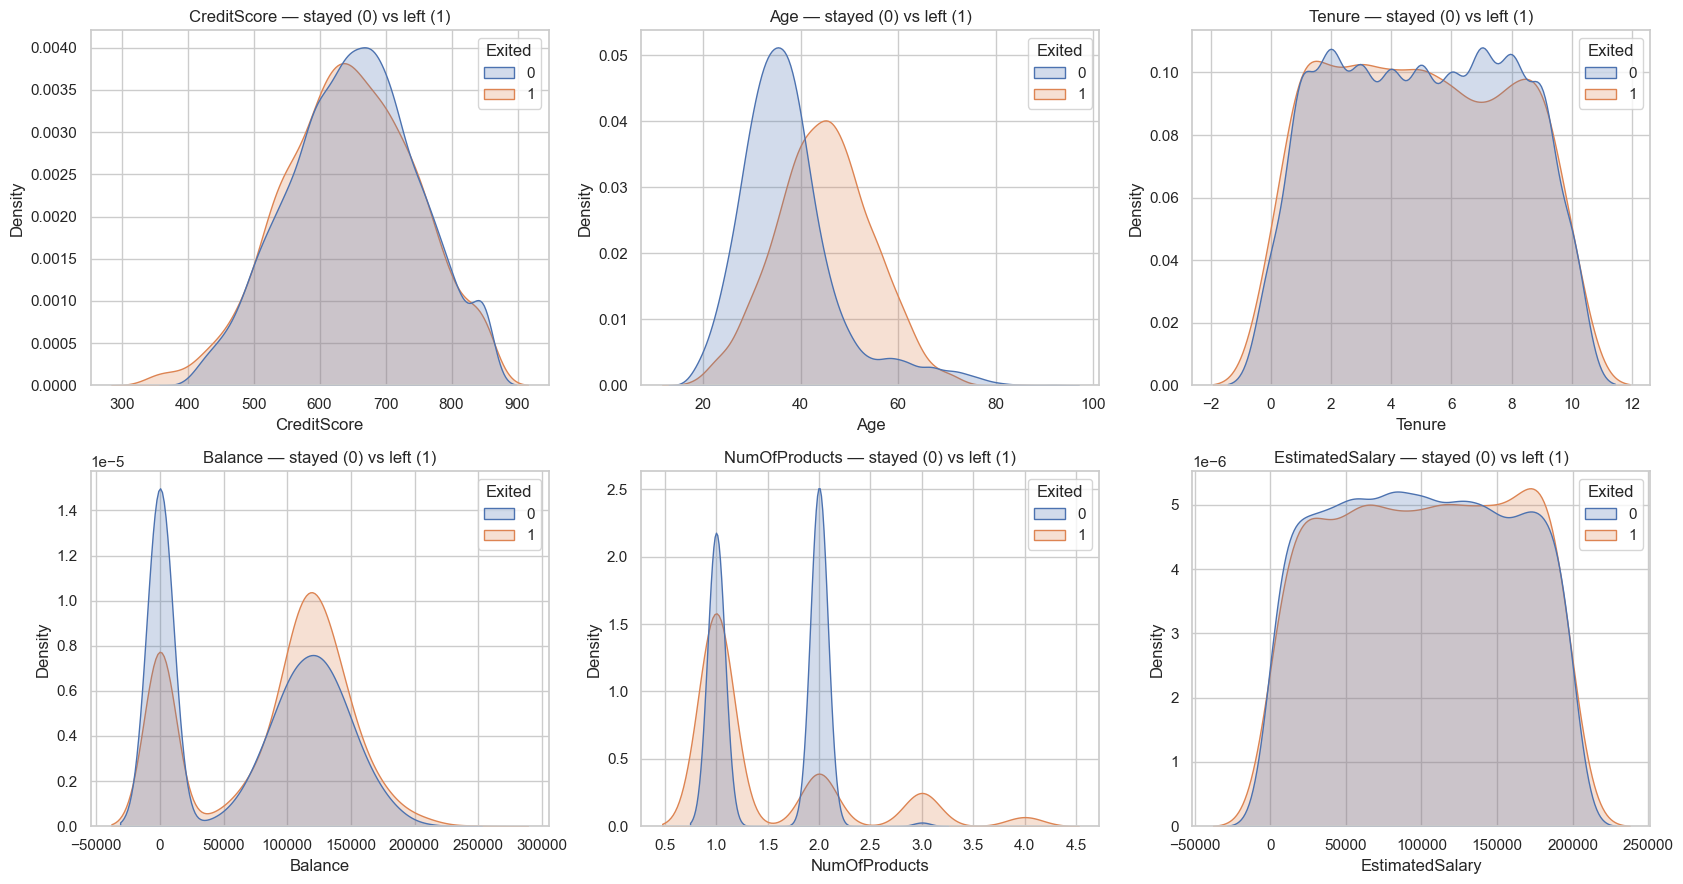

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=df, x=col, hue=target, common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} — stayed (0) vs left (1)")
plt.tight_layout()
plt.show()

In [46]:
df.groupby(target)[num_cols].mean().round(1)

,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
Exited,,,,,,
0,651.9,37.4,5.0,72745.3,1.5,99738.4
1,645.4,44.8,4.9,91108.5,1.5,101465.7


**Observations**
- **Age** is the clearest separator: churned customers are clearly older (average age about 45 versus about 37 for customers who stayed).
- **Balance:** churned customers have a higher average balance.
- `CreditScore`, `Tenure` and `EstimatedSalary` look almost identical for both groups, so they are weak predictors on their own.

### 7.3 Churn by age group

       count  churn_rate_%
Age                       
18-25    611           7.5
26-35   3542           8.5
36-45   3736          19.6
46-55   1311          50.6
56-65    536          48.3
65+      264          13.3


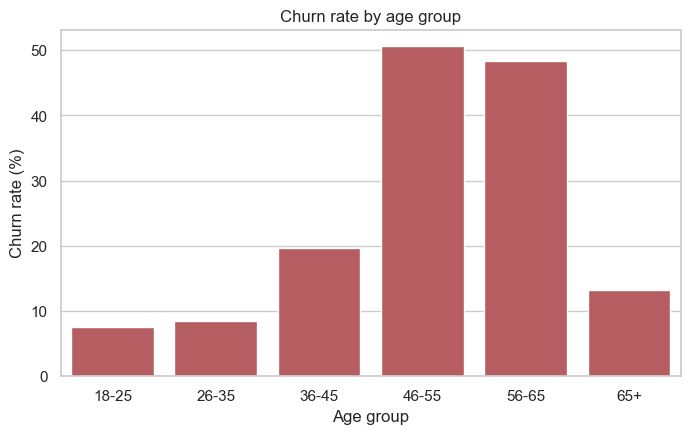

In [47]:
age_bins = [17, 25, 35, 45, 55, 65, 100]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "65+"]
age_group = pd.cut(df["Age"], bins=age_bins, labels=age_labels)

age_churn = df.groupby(age_group)[target].agg(["count", "mean"])
age_churn["mean"] = (age_churn["mean"] * 100).round(1)
print(age_churn.rename(columns={"mean": "churn_rate_%"}))

plt.figure(figsize=(8, 4.5))
sns.barplot(x=age_churn.index.astype(str), y=age_churn["mean"], color="#c44e52")
plt.title("Churn rate by age group")
plt.ylabel("Churn rate (%)")
plt.xlabel("Age group")
plt.show()

**Observation:** churn jumps to about **50% for customers aged 46–65**, while customers under 35 rarely leave (under 10%) and the 65+ group drops back down.

### 7.4 Balance, geography and gender together

Churn rate by zero-balance flag:
ZeroBalance
0    24.1
1    13.8
Name: Exited, dtype: float64

Average balance by geography:
Geography
France      62093.0
Germany    119730.0
Spain       61818.0
Name: Balance, dtype: float64


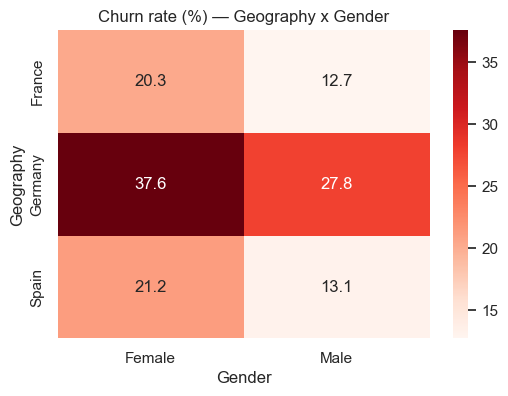

In [48]:
df["ZeroBalance"] = (df["Balance"] == 0).astype(int)

print("Churn rate by zero-balance flag:")
print((df.groupby("ZeroBalance")[target].mean() * 100).round(1))
print()
print("Average balance by geography:")
print(df.groupby("Geography")["Balance"].mean().round(0))

pivot = df.pivot_table(index="Geography", columns="Gender", values=target, aggfunc="mean") * 100
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn rate (%) — Geography x Gender")
plt.show()

df = df.drop(columns="ZeroBalance")   # helper column only used for this analysis

**Observations**
- About half of the French and Spanish customers hold a zero balance, whereas **every German customer has a non-zero balance** and the average balance is about twice as high. Customers with a balance churn more, which fits with Germany's high churn rate.
- Within every country, women churn more than men, and Germany is the highest for both genders.

## 8. Correlation analysis

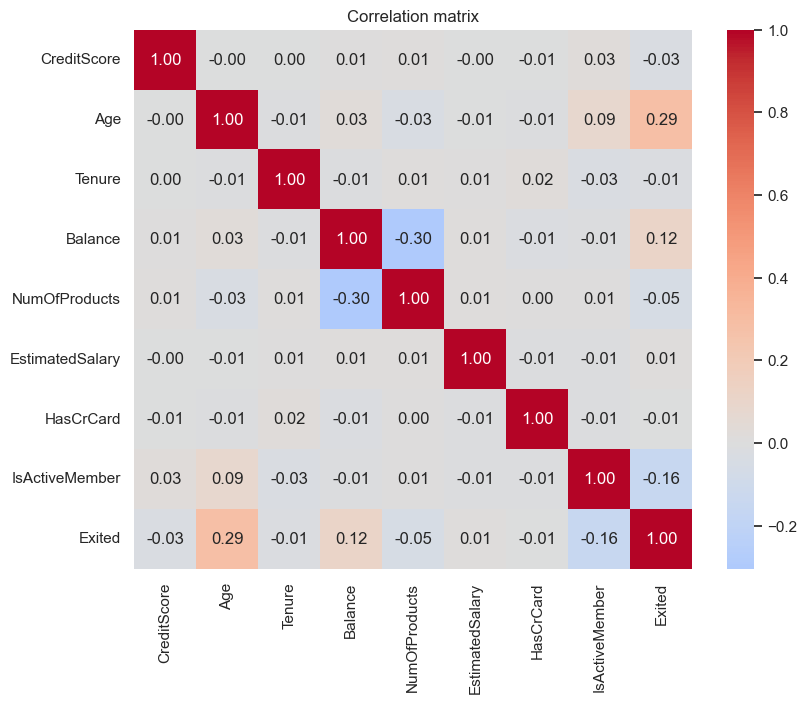

Correlation with churn:
Age                0.285
IsActiveMember    -0.156
Balance            0.119
NumOfProducts     -0.048
CreditScore       -0.027
Tenure            -0.014
EstimatedSalary    0.012
HasCrCard         -0.007
Name: Exited, dtype: float64


In [49]:
corr = df[num_cols + ["HasCrCard", "IsActiveMember", target]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print("Correlation with churn:")
print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

**Observations**
- `Age` has the strongest correlation with churn, followed by `IsActiveMember` (negative) and `Balance`.
- The input features are not strongly correlated with each other, so **multicollinearity is not a concern** for Logistic Regression.
- Correlation only captures *linear* relationships, so tree-based models may find patterns (like the `NumOfProducts` effect) that this matrix hides.

## 9. Outlier check

        feature  lower_bound  upper_bound  outliers  percent
    CreditScore        383.0        919.0        15     0.15
            Age         14.0         62.0       359     3.59
         Tenure         -3.0         13.0         0     0.00
        Balance    -191466.4     319110.6         0     0.00
  NumOfProducts         -0.5          3.5        60     0.60
EstimatedSalary     -96577.1     296967.5         0     0.00


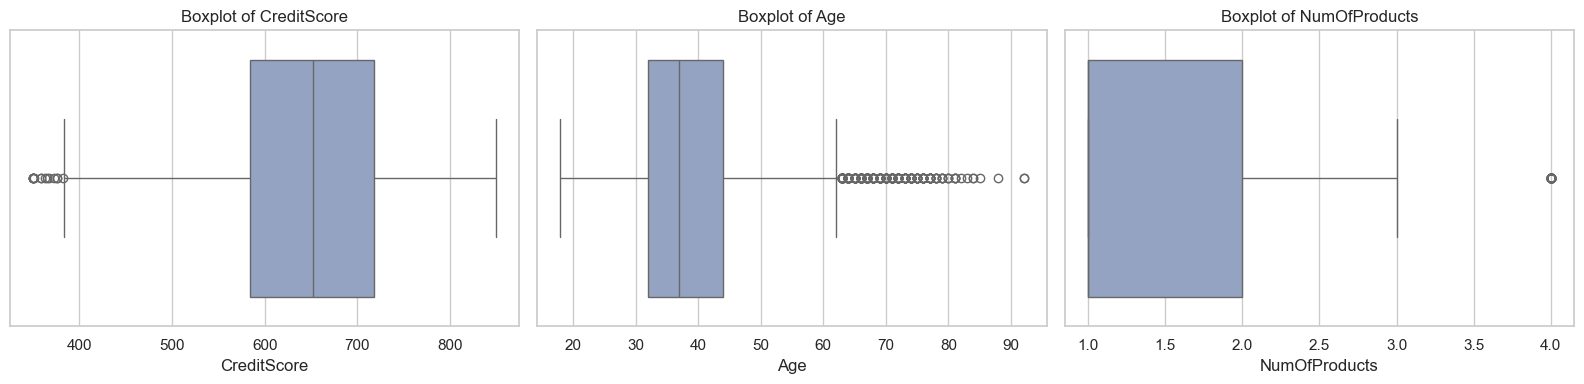

In [42]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append({"feature": col, "lower_bound": round(low, 1), "upper_bound": round(high, 1),
                 "outliers": n_out, "percent": round(n_out / len(df) * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["CreditScore", "Age", "NumOfProducts"]):
    sns.boxplot(x=df[col], ax=ax, color="#8da0cb")
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

**Observation:** only `CreditScore`, `Age` and `NumOfProducts` have IQR outliers. These are *real* values (an 80-year-old customer, a 4-product customer) and — especially for `Age` and `NumOfProducts` — they carry churn information, so **we keep them** instead of removing them.

## 10. Summary of key findings

1. The dataset is clean: **10,000 customers, no missing values, no duplicates**.
2. The data is **imbalanced** (~20% churn), so we must look at recall/F1/ROC-AUC, not just accuracy.
3. **Strongest churn drivers:** `Age` (older customers), `IsActiveMember` (inactive), `Geography` (Germany), `NumOfProducts` (1 product or 3–4 products), `Gender` (female) and `Balance`.
4. **Weak drivers:** `CreditScore`, `Tenure`, `EstimatedSalary`, `HasCrCard`.
5. `RowNumber`, `CustomerId` and `Surname` are dropped.

### Plan for the next notebook
- Split features/target, then build a **scikit-learn `Pipeline`** with a `ColumnTransformer` (scale numeric columns, one-hot encode `Geography` and `Gender`).
- Train **Logistic Regression, KNN, Decision Tree and Random Forest**.
- Tune each one with **GridSearchCV / RandomizedSearchCV** and save the best pipeline.